In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("C:\\Users\\admin\\Downloads\\OneDrive\\python\\retail-sales-analysis\\Data\\retail_sales_dataset.csv")

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

First five rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


Dataset shape: (1000, 9)
Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Qua

In [10]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Updated data types:")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Transaction IDs:", df["Transaction ID"].duplicated().sum())

print("\nNumerical summary:")
display(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].describe())

df["Calculated Amount"] = df["Quantity"] * df["Price per Unit"]

print(
    "\nTransactions where Total Amount does not match:",
    (df["Total Amount"] != df["Calculated Amount"]).sum()
)

Updated data types:
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

Duplicate rows: 0
Duplicate Transaction IDs: 0

Numerical summary:


,Age,Quantity,Price per Unit,Total Amount
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,41.39200,2.514000,179.890000,456.000000
std,13.68143,1.132734,189.681356,559.997632
min,18.00000,1.000000,25.000000,25.000000
25%,29.00000,1.000000,30.000000,60.000000
50%,42.00000,3.000000,50.000000,135.000000
75%,53.00000,4.000000,300.000000,900.000000
max,64.00000,4.000000,500.000000,2000.000000



Transactions where Total Amount does not match: 0


In [11]:
total_revenue = df["Total Amount"].sum()
total_transactions = df["Transaction ID"].nunique()
total_units_sold = df["Quantity"].sum()
average_transaction_value = df["Total Amount"].mean()
average_customer_age = df["Age"].mean()

print("===== RETAIL SALES KPI REPORT =====")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Average Transaction Value: ₹{average_transaction_value:,.2f}")
print(f"Average Customer Age: {average_customer_age:.1f} years")

===== RETAIL SALES KPI REPORT =====
Total Revenue: ₹456,000.00
Total Transactions: 1,000
Total Units Sold: 2,514
Average Transaction Value: ₹456.00
Average Customer Age: 41.4 years


In [12]:
category_sales = (
    df.groupby("Product Category")
      .agg(
          Total_Revenue=("Total Amount", "sum"),
          Units_Sold=("Quantity", "sum"),
          Transactions=("Transaction ID", "nunique")
      )
      .sort_values("Total_Revenue", ascending=False)
)

category_sales["Revenue_Percentage"] = (
    category_sales["Total_Revenue"] / total_revenue * 100
).round(2)

display(category_sales)

,Total_Revenue,Units_Sold,Transactions,Revenue_Percentage
Product Category,,,,
Electronics,156905,849,342,34.41
Clothing,155580,894,351,34.12
Beauty,143515,771,307,31.47


In [13]:
best_category = category_sales["Total_Revenue"].idxmax()

print("Best-performing category:", best_category)
print(
    "Revenue generated:",
    f"₹{category_sales.loc[best_category, 'Total_Revenue']:,.2f}"
)

Best-performing category: Electronics
Revenue generated: ₹156,905.00


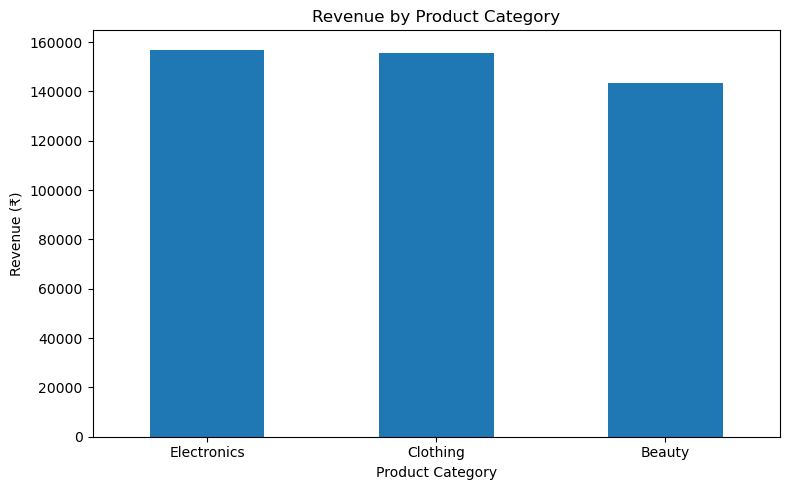

In [14]:
category_sales["Total_Revenue"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Revenue by Product Category"
)

plt.xlabel("Product Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

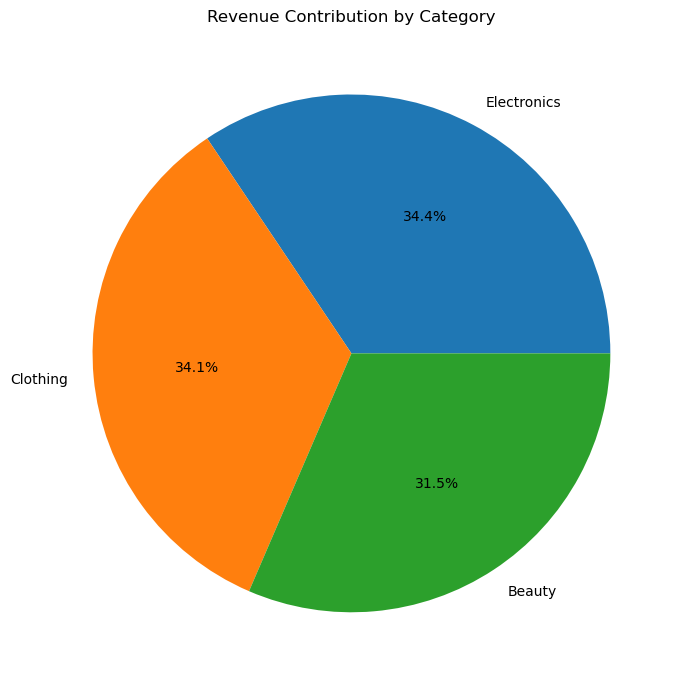

In [15]:
category_sales["Total_Revenue"].plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    ylabel="",
    title="Revenue Contribution by Category"
)

plt.tight_layout()
plt.show()

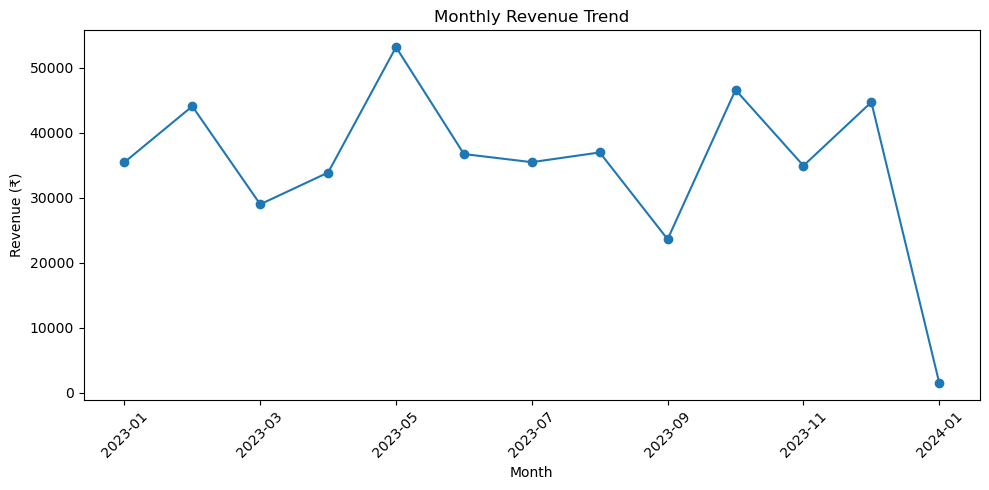

In [16]:
df["Date"] = pd.to_datetime(df["Date"])

monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Total Amount"]
      .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
gender_sales = df.groupby("Gender").agg(
    Customers=("Customer ID", "nunique"),
    Transactions=("Transaction ID", "nunique"),
    Total_Revenue=("Total Amount", "sum"),
    Average_Spending=("Total Amount", "mean")
).sort_values("Total_Revenue", ascending=False)

display(gender_sales)

,Customers,Transactions,Total_Revenue,Average_Spending
Gender,,,,
Female,510,510,232840,456.549020
Male,490,490,223160,455.428571


In [18]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=[
        "Under 20",
        "21-30",
        "31-40",
        "41-50",
        "51-60",
        "Above 60"
    ],
    include_lowest=True
)

age_sales = df.groupby("Age Group", observed=False).agg(
    Transactions=("Transaction ID", "nunique"),
    Total_Revenue=("Total Amount", "sum"),
    Average_Spending=("Total Amount", "mean")
)

display(age_sales)

,Transactions,Total_Revenue,Average_Spending
Age Group,,,
Under 20,63,34730,551.269841
21-30,210,98215,467.690476
31-40,193,95950,497.150259
41-50,221,93795,424.411765
51-60,220,100085,454.931818
Above 60,93,33225,357.258065


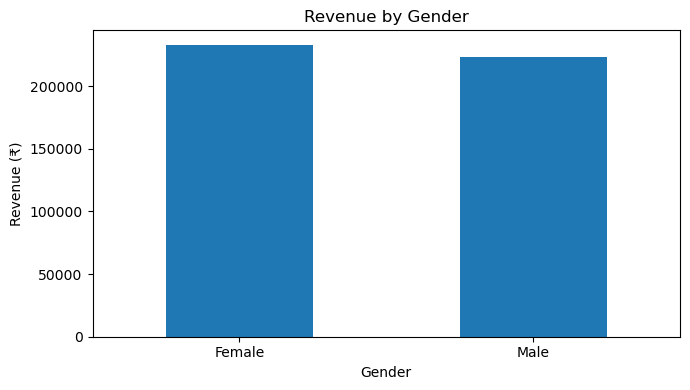

In [19]:
gender_sales["Total_Revenue"].plot(
    kind="bar",
    figsize=(7, 4),
    title="Revenue by Gender"
)

plt.xlabel("Gender")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

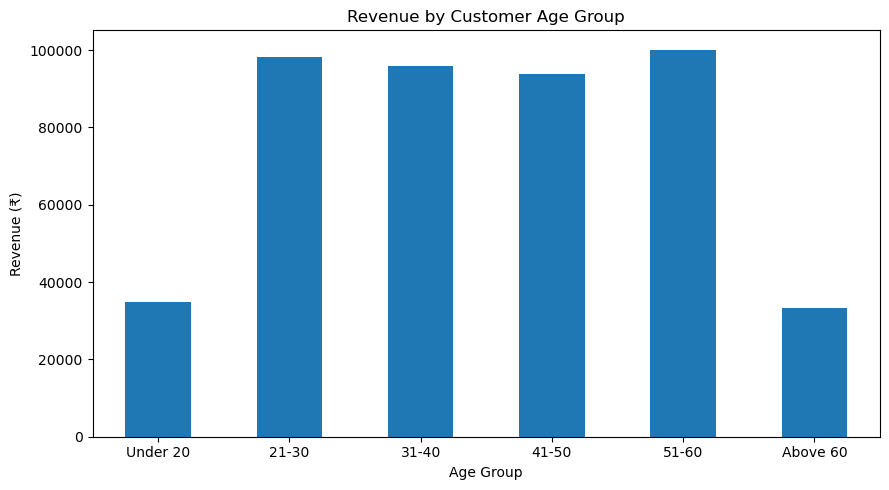

In [20]:
age_sales["Total_Revenue"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Revenue by Customer Age Group"
)

plt.xlabel("Age Group")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
gender_category = pd.pivot_table(
    df,
    values="Total Amount",
    index="Product Category",
    columns="Gender",
    aggfunc="sum",
    fill_value=0
)

display(gender_category)

Gender,Female,Male
Product Category,,
Beauty,74830,68685
Clothing,81275,74305
Electronics,76735,80170


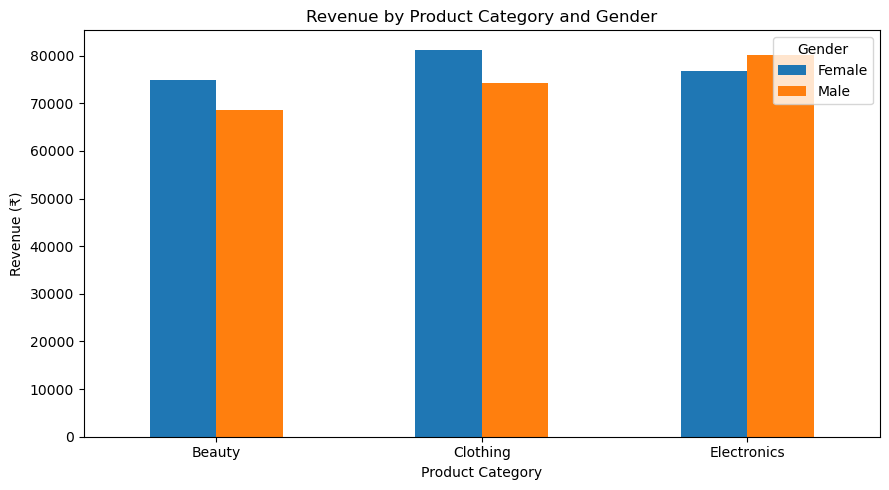

In [22]:
gender_category.plot(
    kind="bar",
    figsize=(9, 5),
    title="Revenue by Product Category and Gender"
)

plt.xlabel("Product Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

In [23]:
print("Top category for each gender:")

for gender in gender_category.columns:
    top_category = gender_category[gender].idxmax()
    revenue = gender_category[gender].max()

    print(f"{gender}: {top_category} — ₹{revenue:,.0f}")

Top category for each gender:
Female: Clothing — ₹81,275
Male: Electronics — ₹80,170
